### Import libraries

In [1]:
from pathlib import Path
from PIL import Image
import pandas as pd
import json
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

### Set paths and training configuration

In [13]:
def find_project_root():
    current_path = Path.cwd().resolve()
    for path in [current_path, *current_path.parents]:

        if (
            (path / ".git").exists()
            or (
                (path / "data").is_dir()
                and (
                    (path / "notebook").is_dir()
                    or (path / "notebooks").is_dir()
                )
            )
        ):
            return path

    raise FileNotFoundError(
        "Project root not found. "
        "Please run this notebook inside the project directory."
    )


ROOT = find_project_root()

print("Project Root:", ROOT)

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

CLEAN_CSV_PATH = PROCESSED_DIR / "rice_leaf_images_clean.csv"

TRAIN_PATH = PROCESSED_DIR / "train.csv"
VALIDATION_PATH = PROCESSED_DIR / "validation.csv"
TEST_PATH = PROCESSED_DIR / "test.csv"

MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
BATCH_SIZE = 16
EPOCHS = 15
LEARNING_RATE = 0.0001
PATIENCE = 5
SEED = 42

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Image Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Epochs:", EPOCHS)

Project Root: D:\My_Project\Analyse\AI-Paddy-Farming-Intelligence
Selected Device: cuda
GPU: NVIDIA GeForce RTX 5050 Laptop GPU
Image Size: 224
Batch Size: 16
Epochs: 15


### Load CSV files and class mapping

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(VALIDATION_PATH)

with open(
    PROCESSED_DIR / "class_mapping.json",
    "r",
    encoding="utf-8"
) as file:
    class_to_idx = json.load(file)

num_classes = len(class_to_idx)

idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

print("Number of classes:", num_classes)
print("Training images:", len(train_df))
print("Validation images:", len(validation_df))
print("Classes:", class_to_idx)


Number of classes: 10
Training images: 4697
Validation images: 1007
Classes: {'Healthy': 0, 'bacterial_leaf_blight': 1, 'brown_spot': 2, 'leaf_blast': 3, 'leaf_scald': 4, 'narrow_brown_spot': 5, 'neck_blast': 6, 'rice_hispa': 7, 'sheath_blight': 8, 'tungro': 9}


### Image preprocessing

In [4]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

validation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


### Create custom image dataset

In [5]:
class RiceLeafDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = ROOT / row["image_path"]
        label = class_to_idx[row["label"]]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


train_dataset = RiceLeafDataset(
    train_df,
    transform=train_transform
)

validation_dataset = RiceLeafDataset(
    validation_df,
    transform=validation_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(validation_dataset))


Training dataset: 4697
Validation dataset: 1007


### Create DataLoaders

In [6]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

print("DataLoaders created successfully!")


DataLoaders created successfully!


### Load EfficientNet model

In [7]:
USE_PRETRAINED = True

weights = (
    EfficientNet_B0_Weights.DEFAULT
    if USE_PRETRAINED
    else None
)

model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    num_classes
)

model = model.to(device)

print(model.classifier)
print("\nModel ready!")


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=10, bias=True)
)

Model ready!


### Define loss function and optimizer

In [8]:
class_counts = train_df["label"].value_counts()

class_weights = [
    len(train_df) / (
        num_classes * class_counts[idx_to_class[i]]
    )
    for i in range(num_classes)
]

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Loss function and optimizer ready!")


Loss function and optimizer ready!


### Training and validation functions

In [9]:
def train_one_epoch(model, loader):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


def evaluate_one_epoch(model, loader):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy


### Train the model


In [10]:
history = []

best_val_accuracy = -1.0
early_stop_count = 0

MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "rice_disease_model.pth"

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_accuracy = evaluate_one_epoch(
        model,
        validation_loader
    )

    scheduler.step(val_accuracy)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy
    })

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Save the best model based on validation accuracy.
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy
        early_stop_count = 0

        checkpoint = {
            "model_state_dict": model.state_dict(),
            "class_to_idx": class_to_idx,
            "image_size": IMAGE_SIZE,
            "mean": [0.485, 0.456, 0.406],
            "std": [0.229, 0.224, 0.225]
        }
        temporary_path = MODEL_PATH.with_suffix(".pth.tmp")
        torch.save(checkpoint, temporary_path)
        temporary_path.replace(MODEL_PATH)

        print("Best model saved!")

    else:
        early_stop_count += 1

    if early_stop_count >= PATIENCE:
        print("Early stopping activated.")
        break


if not MODEL_PATH.is_file():
    raise RuntimeError(
        "Training ended without saving a checkpoint. "
        "Check that validation data was loaded and training completed an epoch."
    )

print("\nTraining completed!")
print("Best validation accuracy:", best_val_accuracy)
print(f"Model saved: {MODEL_PATH} ({MODEL_PATH.stat().st_size / (1024 ** 2):.2f} MB)")


Epoch [1/15] Train Loss: 1.0806 Train Acc: 0.6838 Val Loss: 0.3023 Val Acc: 0.9067
Best model saved!
Epoch [2/15] Train Loss: 0.3540 Train Acc: 0.8891 Val Loss: 0.2033 Val Acc: 0.9295
Best model saved!
Epoch [3/15] Train Loss: 0.2098 Train Acc: 0.9368 Val Loss: 0.1220 Val Acc: 0.9603
Best model saved!
Epoch [4/15] Train Loss: 0.1658 Train Acc: 0.9481 Val Loss: 0.0990 Val Acc: 0.9702
Best model saved!
Epoch [5/15] Train Loss: 0.1089 Train Acc: 0.9653 Val Loss: 0.0952 Val Acc: 0.9762
Best model saved!
Epoch [6/15] Train Loss: 0.0960 Train Acc: 0.9715 Val Loss: 0.0714 Val Acc: 0.9811
Best model saved!
Epoch [7/15] Train Loss: 0.0678 Train Acc: 0.9793 Val Loss: 0.0823 Val Acc: 0.9762
Epoch [8/15] Train Loss: 0.0626 Train Acc: 0.9828 Val Loss: 0.1045 Val Acc: 0.9712
Epoch [9/15] Train Loss: 0.0517 Train Acc: 0.9840 Val Loss: 0.0855 Val Acc: 0.9752
Epoch [10/15] Train Loss: 0.0414 Train Acc: 0.9877 Val Loss: 0.0739 Val Acc: 0.9811
Epoch [11/15] Train Loss: 0.0319 Train Acc: 0.9915 Val Loss: 

### Save training history

In [11]:
history_df = pd.DataFrame(history)

history_df.to_csv(
    MODEL_DIR / "training_history.csv",
    index=False
)

display(history_df)


,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,1,1.080646,0.683841,0.302326,0.906653
1,2,0.353974,0.889078,0.203264,0.929494
2,3,0.209824,0.936768,0.122001,0.960278
3,4,0.165755,0.948052,0.099011,0.970209
4,5,0.108892,0.965297,0.095185,0.976167
5,6,0.095964,0.971471,0.071392,0.981132
6,7,0.067777,0.979349,0.082349,0.976167
7,8,0.062553,0.982755,0.104510,0.971202
8,9,0.051696,0.984032,0.085494,0.975174
9,10,0.041410,0.987652,0.073894,0.981132


### Display training graphs

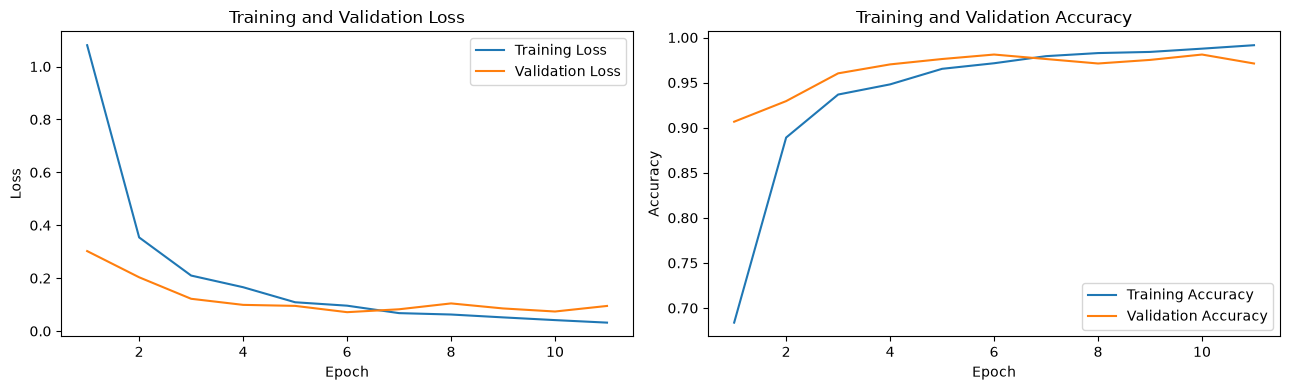

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Loss"
)

axes[0].plot(
    history_df["epoch"],
    history_df["validation_loss"],
    label="Validation Loss"
)

axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    label="Training Accuracy"
)

axes[1].plot(
    history_df["epoch"],
    history_df["validation_accuracy"],
    label="Validation Accuracy"
)

axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()
